# Example of the aitlas toolbox in the context of change detection

## Import the required packages

In [ ]:
from aitlas.datasets import LEVIRCDPlusDataset
from aitlas.utils import image_loader
from aitlas.models import UnetChangeDetection
from aitlas.transforms import MinMaxNormTranspose, ResizeToTensor

## Visualize images and masks

Total number of patches: 637


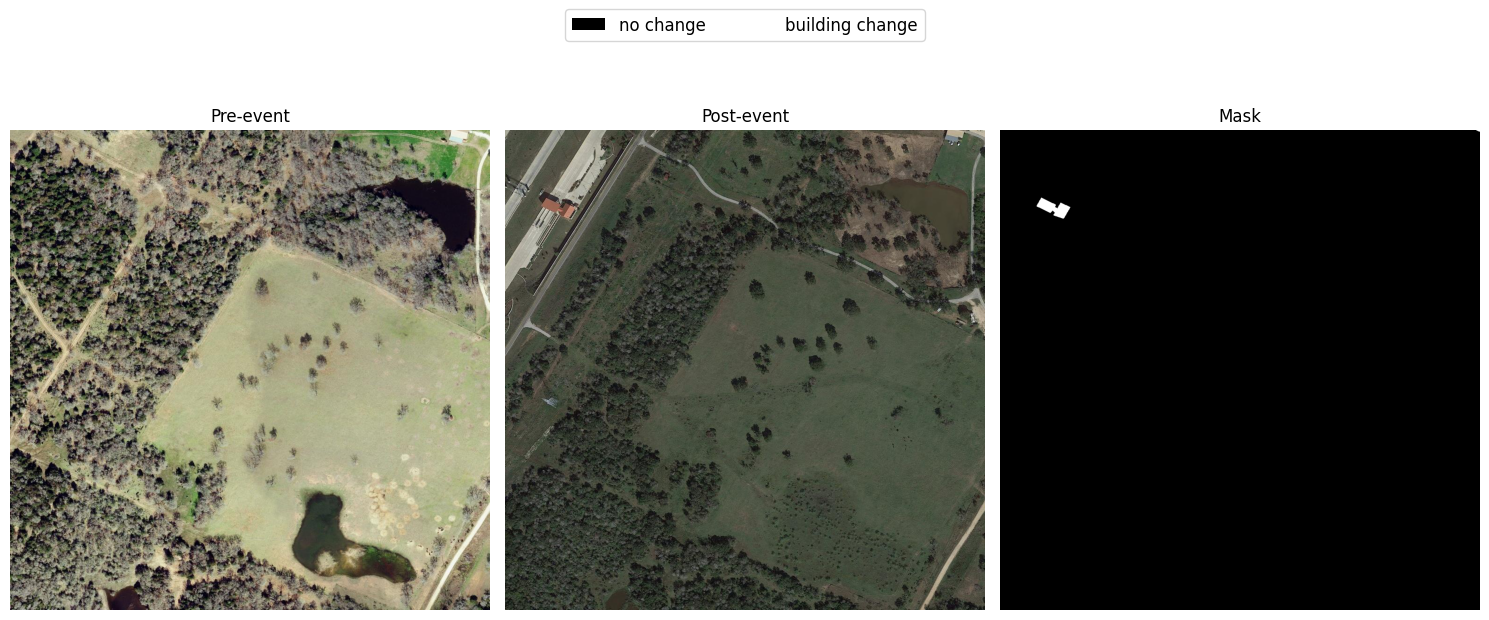

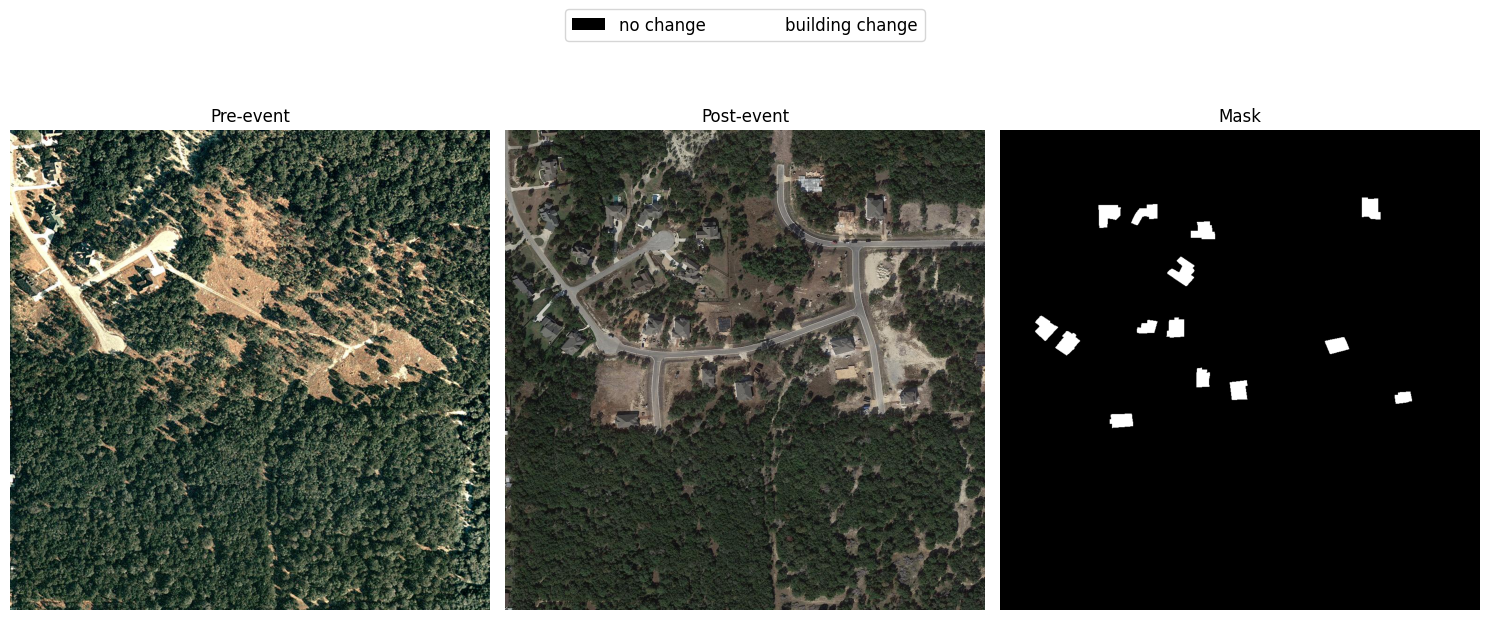

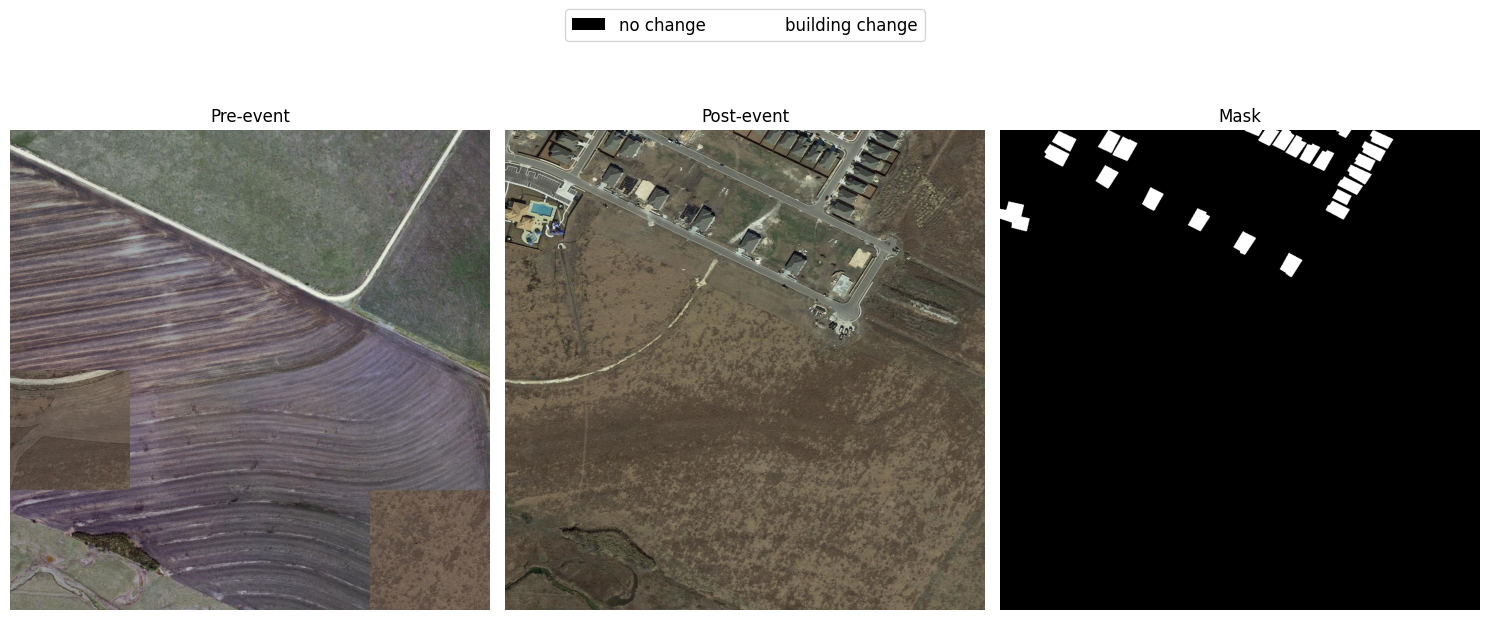

In [9]:
dataset_config = {
    "data_dir" : "/home/dragik/data/FAIR_EO/levir_cd+/train/",
}
dataset = LEVIRCDPlusDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

dataset.show_image(100);
dataset.show_image(15);
dataset.show_image(22);

In [12]:
dataset.data_distribution_table()

,Number of pixels
no change,592528148.0
building change,27180268.0


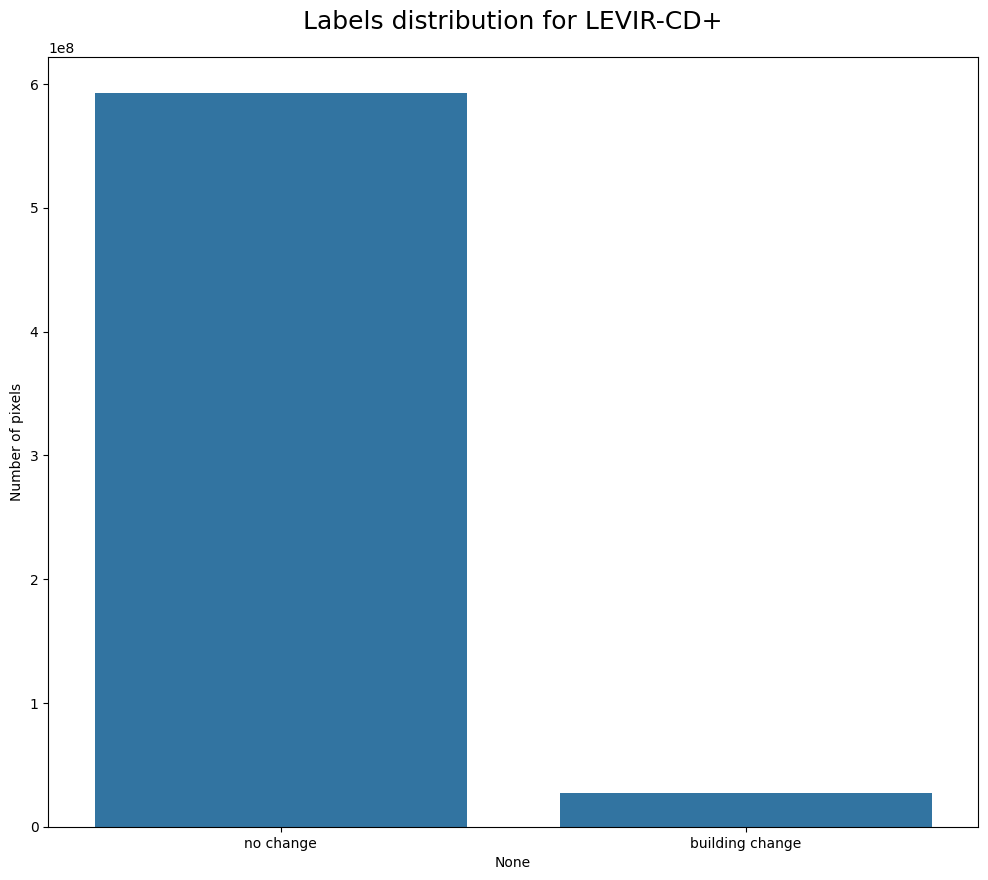

In [13]:
dataset.data_distribution_barchart();

## Load training and test data

New 60/20/20 train/val/test splits

In [14]:
train_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "/home/dragik/data/FAIR_EO/levir_cd+/",
    "csv_file": "/home/dragik/data/FAIR_EO/levir_cd+/levir_cdplus_train.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
train_dataset = LEVIRCDPlusDataset(train_dataset_config)

test_dataset_config = {
    "batch_size": 16,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "/home/dragik/data/FAIR_EO/levir_cd+/",
    "csv_file": "/home/dragik/data/FAIR_EO/levir_cd+/levir_cdplus_val.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
test_dataset = LEVIRCDPlusDataset(test_dataset_config)
len(train_dataset), len(test_dataset)

(591, 197)

Original train/test splits

In [ ]:
train_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "/home/dragik/data/FAIR_EO/levir_cd+/train/",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
train_dataset = LEVIRCDPlusDataset(train_dataset_config)

test_dataset_config = {
    "batch_size": 16,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "/home/dragik/data/FAIR_EO/levir_cd+/test/",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
test_dataset = LEVIRCDPlusDataset(test_dataset_config)
len(train_dataset), len(test_dataset)

## Create the model

In [ ]:
epochs = 50
model_directory = "/home/dragik/data/FAIR_EO/experiments/levir_cd_plus"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": False, 
    "threshold": 0.5,
    "metrics": ["accuracy", "precision", "recall", "f1_score", "iou"]
}

model = UnetChangeDetection(model_config)
model.prepare()

## Start the training

In [10]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1',
)

model_path = model_directory + "/checkpoint.pth.tar"
model.load_model(model_path)
model.running_metrics.reset()
model.evaluate(dataset=test_dataset, model_path=model_path)
test_metrics = model.running_metrics.get_scores(model.metrics)

2026-01-26 09:16:58,723 INFO Starting training.
training: 100%|██████████| 20/20 [04:31<00:00, 13.59s/it]
2026-01-26 09:21:30,518 INFO epoch: 1, loss:  0.27777
testing on train set: 100%|██████████| 20/20 [04:40<00:00, 14.00s/it]
2026-01-26 09:26:11,710 INFO Accuracy:0.4883515434325022, Accuracy per Class:[0.93068897 0.04601411], Precision Micro:0.4830908705820625, Precision Macro:0.478211082470869, Precision Weighted:0.9063774640931923, Precision per Class:[0.93068897 0.02573319], Recall Micro:0.9994677842537776, Recall Macro:0.990094574461539, Recall Weighted:0.9994677842537776, Recall per Class:[1.         0.98018915], F1_score Micro:0.6513519858913711, F1_score Macro:0.5071250753393372, F1_score Weighted:0.9395472124920128, F1_score per Class:[0.96410037 0.05014978], IOU:0.48296662960044046, IOU mean:0.47820439403315446, IOU per Class:[0.93068897 0.02571981]
training: 100%|██████████| 20/20 [04:42<00:00, 14.12s/it]
2026-01-26 09:30:54,094 INFO epoch: 2, loss:  0.24500
testing on tr

## Predictions

2026-01-29 13:25:29,804 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/levir_cd_plus/checkpoint.pth.tar
2026-01-29 13:25:30,203 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/levir_cd_plus/checkpoint.pth.tar at epoch 51


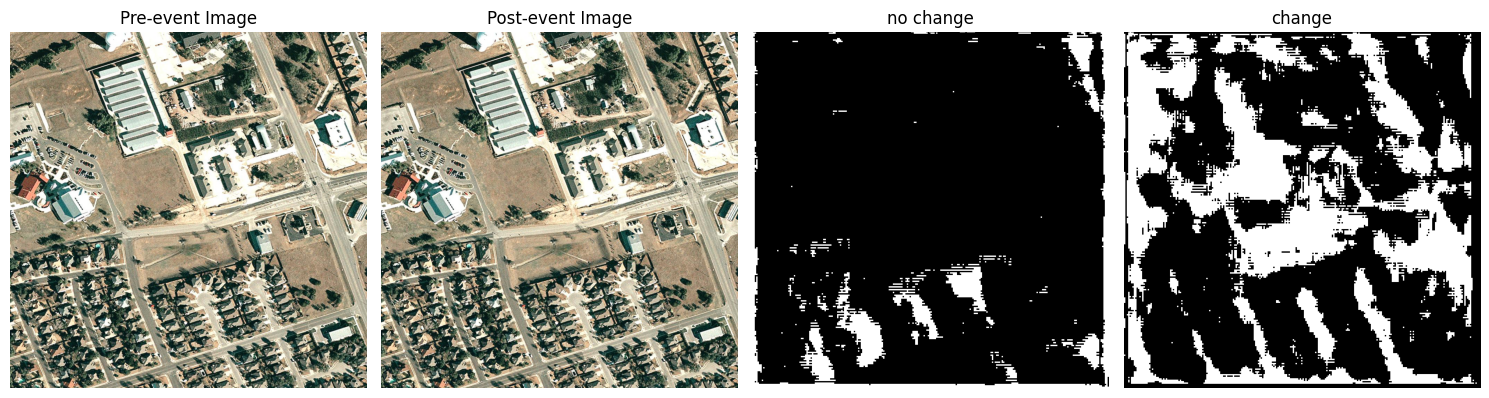

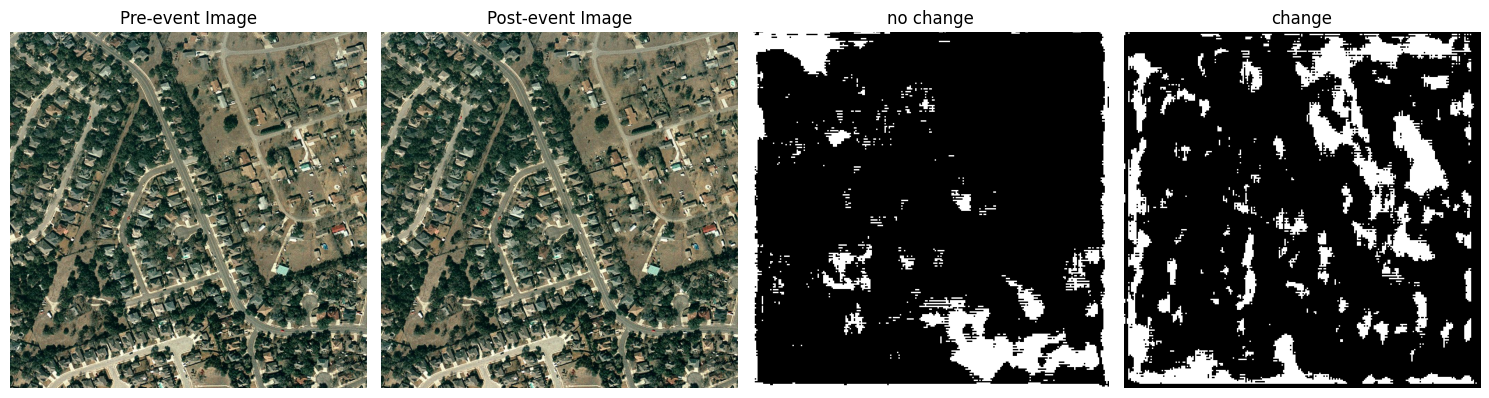

In [17]:
model_path = "/home/dragik/data/FAIR_EO/experiments/levir_cd_plus/checkpoint.pth.tar"
labels = ["no change","change"]
transform = ResizeToTensor()
model.load_model(model_path)

image1 = image_loader("/home/dragik/data/FAIR_EO/levir_cd+/test/A/train_799.png")
image2 = image_loader("/home/dragik/data/FAIR_EO/levir_cd+/test/A/train_799.png")
fig = model.predict_masks(image1, image2, labels, transform)

image1 = image_loader("/home/dragik/data/FAIR_EO/levir_cd+/test/A/train_800.png")
image2 = image_loader("/home/dragik/data/FAIR_EO/levir_cd+/test/A/train_800.png")
fig = model.predict_masks(image1, image2, labels, transform)